# CHƯƠNG 4: TIỀN XỬ LÝ DỮ LIỆU, GIẢM CHIỀU PCA VÀ LẤY MẪU THỐNG NHẤT
Notebook này thực hiện toàn bộ quy trình:
1. Tách bộ đặc trưng X (561 cột) và nhãn hoạt động y.
2. Kiểm tra dữ liệu thiếu và bất thường.
3. Chuẩn hóa dữ liệu bằng .
4. Phân tích thành phần chính (PCA) và khảo sát phương sai tích lũy.
5. Trực quan hóa dữ liệu trên không gian PCA 2D.
6. Lấy mẫu phân tầng 3.000 dòng (, ) dùng chung cho K-Means và Hierarchical Clustering.
7. Xuất file chỉ số dòng và cấu hình tiền xử lý.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split

DATA_RAW = '../data/raw/UCI HAR Dataset'
DATA_PROCESSED = '../data/processed'
RESULTS_DIR = '../results'
FIGURES_DIR = '../results/figures'

os.makedirs(DATA_PROCESSED, exist_ok=True)
os.makedirs(FIGURES_DIR, exist_ok=True)

### Bước 1: Nạp dữ liệu và xác định danh sách đặc trưng đầu vào

In [2]:
# Đọc danh sách 561 đặc trưng
features_df = pd.read_csv(f'{DATA_RAW}/features.txt', sep=r'\s+', header=None, names=['Index', 'Feature'])
feature_names = features_df['Feature'].tolist()

# Đọc nhãn hoạt động
activity_labels_df = pd.read_csv(f'{DATA_RAW}/activity_labels.txt', sep=r'\s+', header=None, names=['Activity', 'ActivityName'])
activity_dict = dict(zip(activity_labels_df['Activity'], activity_labels_df['ActivityName']))

# Đọc tập Train
X_train = pd.read_csv(f'{DATA_RAW}/train/X_train.txt', sep=r'\s+', header=None)
X_train.columns = feature_names
y_train = pd.read_csv(f'{DATA_RAW}/train/y_train.txt', header=None, names=['Activity'])
subject_train = pd.read_csv(f'{DATA_RAW}/train/subject_train.txt', header=None, names=['Subject'])
train_data = pd.concat([subject_train, y_train, X_train], axis=1)

# Đọc tập Test
X_test = pd.read_csv(f'{DATA_RAW}/test/X_test.txt', sep=r'\s+', header=None)
X_test.columns = feature_names
y_test = pd.read_csv(f'{DATA_RAW}/test/y_test.txt', header=None, names=['Activity'])
subject_test = pd.read_csv(f'{DATA_RAW}/test/subject_test.txt', header=None, names=['Subject'])
test_data = pd.concat([subject_test, y_test, X_test], axis=1)

# Gộp dữ liệu
all_data = pd.concat([train_data, test_data], ignore_index=True)
all_data['ActivityName'] = all_data['Activity'].map(activity_dict)
print(f'Kích thước toàn bộ dữ liệu: {all_data.shape}')

Kích thước toàn bộ dữ liệu: (10299, 564)


### Bước 2: Tách bộ đặc trưng X và loại bỏ nhãn hoạt động, đối tượng

In [3]:
# Loại bỏ Subject, Activity, ActivityName khỏi ma trận X
X = all_data.drop(columns=['Subject', 'Activity', 'ActivityName']).copy()
y = all_data['Activity'].copy()
y_name = all_data['ActivityName'].copy()
subjects = all_data['Subject'].copy()

print(f'Shape của X (đặc trưng đầu vào): {X.shape}')
print(f'Shape của y (nhãn thực tế phục vụ đánh giá ngoài): {y.shape}')

Shape của X (đặc trưng đầu vào): (10299, 561)
Shape của y (nhãn thực tế phục vụ đánh giá ngoài): (10299,)


### Bước 3: Kiểm tra dữ liệu thiếu và bất thường

In [4]:
print('Số lượng giá trị NaN trong X:', X.isnull().sum().sum())
print('Số lượng dòng trùng lặp trong X:', X.duplicated().sum())

Số lượng giá trị NaN trong X: 0
Số lượng dòng trùng lặp trong X: 0


### Bước 4: Chuẩn hóa dữ liệu bằng StandardScaler

In [5]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X.values)
print(f'Shape sau chuẩn hóa: {X_scaled.shape}')
print(f'Mean trung bình các đặc trưng: {X_scaled.mean():.4f}, Std trung bình: {X_scaled.std():.4f}')

Shape sau chuẩn hóa: (10299, 561)
Mean trung bình các đặc trưng: 0.0000, Std trung bình: 1.0000


### Bước 5: Phân tích thành phần chính PCA

In [6]:
pca_full = PCA(random_state=42)
pca_full.fit(X_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

# Xác định số lượng PC để đạt >= 95% phương sai tích lũy
n_components_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)
print(f'Số lượng thành phần chính đạt >= 95% phương sai: {n_components_95} (Đạt {cumulative_variance[n_components_95-1]*100:.2f}%)')

Số lượng thành phần chính đạt >= 95% phương sai: 104 (Đạt 95.05%)


### Bước 6: Trực quan hóa phương sai giải thích và PCA 2D

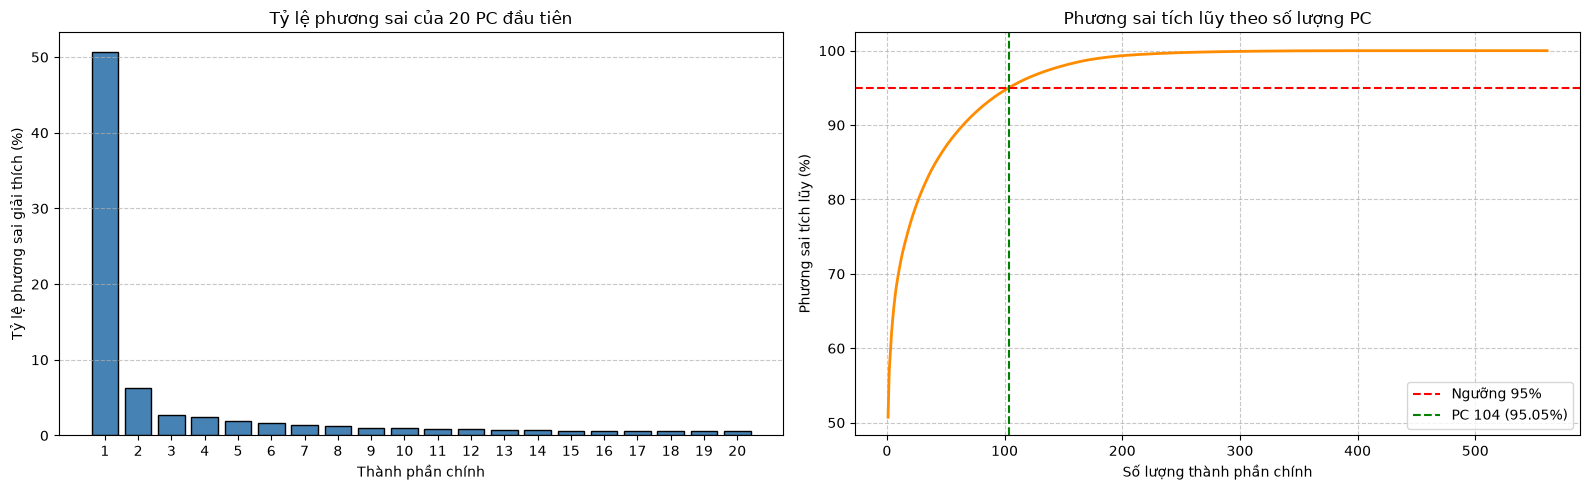

In [7]:
# Biểu đồ Scree plot và Cumulative plot
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 20 PC đầu
axes[0].bar(range(1, 21), explained_variance[:20] * 100, color='steelblue', edgecolor='black')
axes[0].set_xlabel('Thành phần chính')
axes[0].set_ylabel('Tỷ lệ phương sai giải thích (%)')
axes[0].set_title('Tỷ lệ phương sai của 20 PC đầu tiên')
axes[0].set_xticks(range(1, 21))
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Cumulative plot
axes[1].plot(range(1, len(cumulative_variance) + 1), cumulative_variance * 100, color='darkorange', linewidth=2)
axes[1].axhline(y=95, color='red', linestyle='--', label='Ngưỡng 95%')
axes[1].axvline(x=n_components_95, color='green', linestyle='--', label=f'PC {n_components_95} ({cumulative_variance[n_components_95-1]*100:.2f}%)')
axes[1].set_xlabel('Số lượng thành phần chính')
axes[1].set_ylabel('Phương sai tích lũy (%)')
axes[1].set_title('Phương sai tích lũy theo số lượng PC')
axes[1].legend()
axes[1].grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

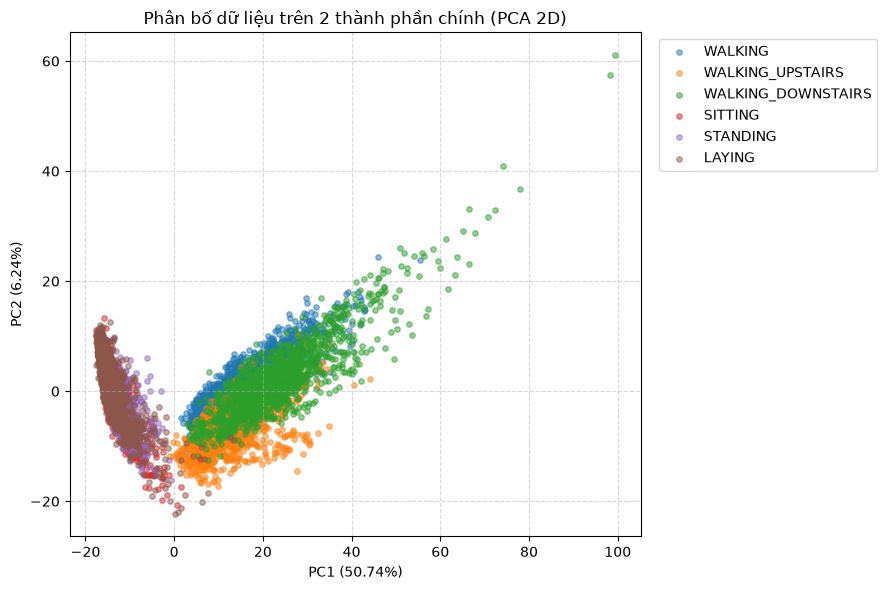

In [8]:
# Trực quan hóa PCA 2D
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))
for act_name in activity_labels_df['ActivityName']:
    mask = (all_data['ActivityName'] == act_name)
    plt.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1], label=act_name, alpha=0.5, s=15)
plt.xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]*100:.2f}%)')
plt.ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]*100:.2f}%)')
plt.title('Phân bố dữ liệu trên 2 thành phần chính (PCA 2D)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Bước 7: Lấy mẫu phân tầng 3.000 dòng thống nhất cho K-Means và Hierarchical Clustering

In [9]:
SAMPLE_SIZE = 3000
RANDOM_STATE = 42

indices = np.arange(len(all_data))
sample_indices, _ = train_test_split(
    indices,
    train_size=SAMPLE_SIZE,
    stratify=y,
    random_state=RANDOM_STATE
)
sample_indices = np.sort(sample_indices)
sampled_data = all_data.iloc[sample_indices].copy()

# So sánh tỷ lệ hoạt động
dist_df = pd.DataFrame({
    'Hoạt động': activity_labels_df['ActivityName'],
    'Số mẫu gốc (N=10.299)': [all_data[all_data['ActivityName'] == name].shape[0] for name in activity_labels_df['ActivityName']],
    'Tỷ lệ gốc (%)': [round(all_data[all_data['ActivityName'] == name].shape[0] / len(all_data) * 100, 2) for name in activity_labels_df['ActivityName']],
    'Số mẫu tập mẫu (N=3.000)': [sampled_data[sampled_data['ActivityName'] == name].shape[0] for name in activity_labels_df['ActivityName']],
    'Tỷ lệ tập mẫu (%)': [round(sampled_data[sampled_data['ActivityName'] == name].shape[0] / SAMPLE_SIZE * 100, 2) for name in activity_labels_df['ActivityName']]
})
print(dist_df.to_string(index=False))

         Hoạt động  Số mẫu gốc (N=10.299)  Tỷ lệ gốc (%)  Số mẫu tập mẫu (N=3.000)  Tỷ lệ tập mẫu (%)
           WALKING                   1722          16.72                       502              16.73
  WALKING_UPSTAIRS                   1544          14.99                       450              15.00
WALKING_DOWNSTAIRS                   1406          13.65                       409              13.63
           SITTING                   1777          17.25                       518              17.27
          STANDING                   1906          18.51                       555              18.50
            LAYING                   1944          18.88                       566              18.87


### Bước 8: Lưu file chỉ số mẫu, dữ liệu chuẩn hóa PCA và cấu hình

In [10]:
# Xuất file sample_indices.csv
sample_indices_df = pd.DataFrame({
    'Sample_Index': np.arange(SAMPLE_SIZE),
    'Original_Index': sample_indices,
    'Subject': sampled_data['Subject'].values,
    'Activity': sampled_data['Activity'].values,
    'ActivityName': sampled_data['ActivityName'].values
})
sample_indices_df.to_csv(f'{DATA_PROCESSED}/sample_indices.csv', index=False)

# Chuyển đổi PCA 104 chiều cho tập mẫu 3.000 dòng
pca_final = PCA(n_components=n_components_95, random_state=RANDOM_STATE)
X_scaled_pca_all = pca_final.fit_transform(X_scaled)
X_sampled_pca = X_scaled_pca_all[sample_indices]

pca_cols = [f'PC{i+1}' for i in range(n_components_95)]
sampled_pca_df = pd.DataFrame(X_sampled_pca, columns=pca_cols)
sampled_pca_df['Activity'] = sampled_data['Activity'].values
sampled_pca_df['ActivityName'] = sampled_data['ActivityName'].values
sampled_pca_df['Subject'] = sampled_data['Subject'].values
sampled_pca_df['Original_Index'] = sample_indices

sampled_pca_df.to_csv(f'{DATA_PROCESSED}/sampled_data_scaled_pca.csv', index=False)
print('Đã lưu dữ liệu tập mẫu và chỉ số thành công!')

Đã lưu dữ liệu tập mẫu và chỉ số thành công!
